# Nam Tu - 153076622 - Exercise 3

# Task 1

## It is possible to visually tell that there is an activity, but without the labels it is difficult (if possible at all) to tell different activites from one another. A possible method is identifying different feature characteristics by averaging across many samples, and use those values as the thresholds for different activities. For example, the time to go into standing position might take longer if the person is lying down rather than sitting.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


data = pd.read_csv("./RawData/acc_exp01_user01.txt",
    sep=r"\s+",
    header=None,
    names=["x", "y", "z"])
data["x"] = data["x"].astype(float)
data["y"] = data["y"].astype(float)
data["z"] = data["z"].astype(float)

labels = pd.read_csv("./RawData/labels.txt",
    sep=r"\s+",
    header=None,
    names=["experiment", "user", "activity","start","end"])
labels["experiment"] = labels["experiment"].astype(int)
labels["user"] = labels["user"].astype(int)
labels["activity"] = labels["activity"].astype(int)
labels["start"] = labels["start"].astype(int)
labels["end"] = labels["end"].astype(int)

activity_names = pd.read_csv(
    "./activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity", "activity_name"]
)

activity_names["activity"] = activity_names["activity"].astype(int)
activity_names["activity_name"] = activity_names["activity_name"].str.strip()

labels = labels.merge(
    activity_names,
    on="activity",
    how="left",
    validate="many_to_one"
)

f = 50 #Hz
labels

,experiment,user,activity,start,end,activity_name
0,1,1,5,250,1232,STANDING
1,1,1,7,1233,1392,STAND_TO_SIT
2,1,1,4,1393,2194,SITTING
3,1,1,8,2195,2359,SIT_TO_STAND
4,1,1,5,2360,3374,STANDING
...,...,...,...,...,...,...
1209,61,30,2,13842,14574,WALKING_UPSTAIRS
1210,61,30,3,14751,15427,WALKING_DOWNSTAIRS
1211,61,30,2,15588,16319,WALKING_UPSTAIRS
1212,61,30,3,16546,17250,WALKING_DOWNSTAIRS


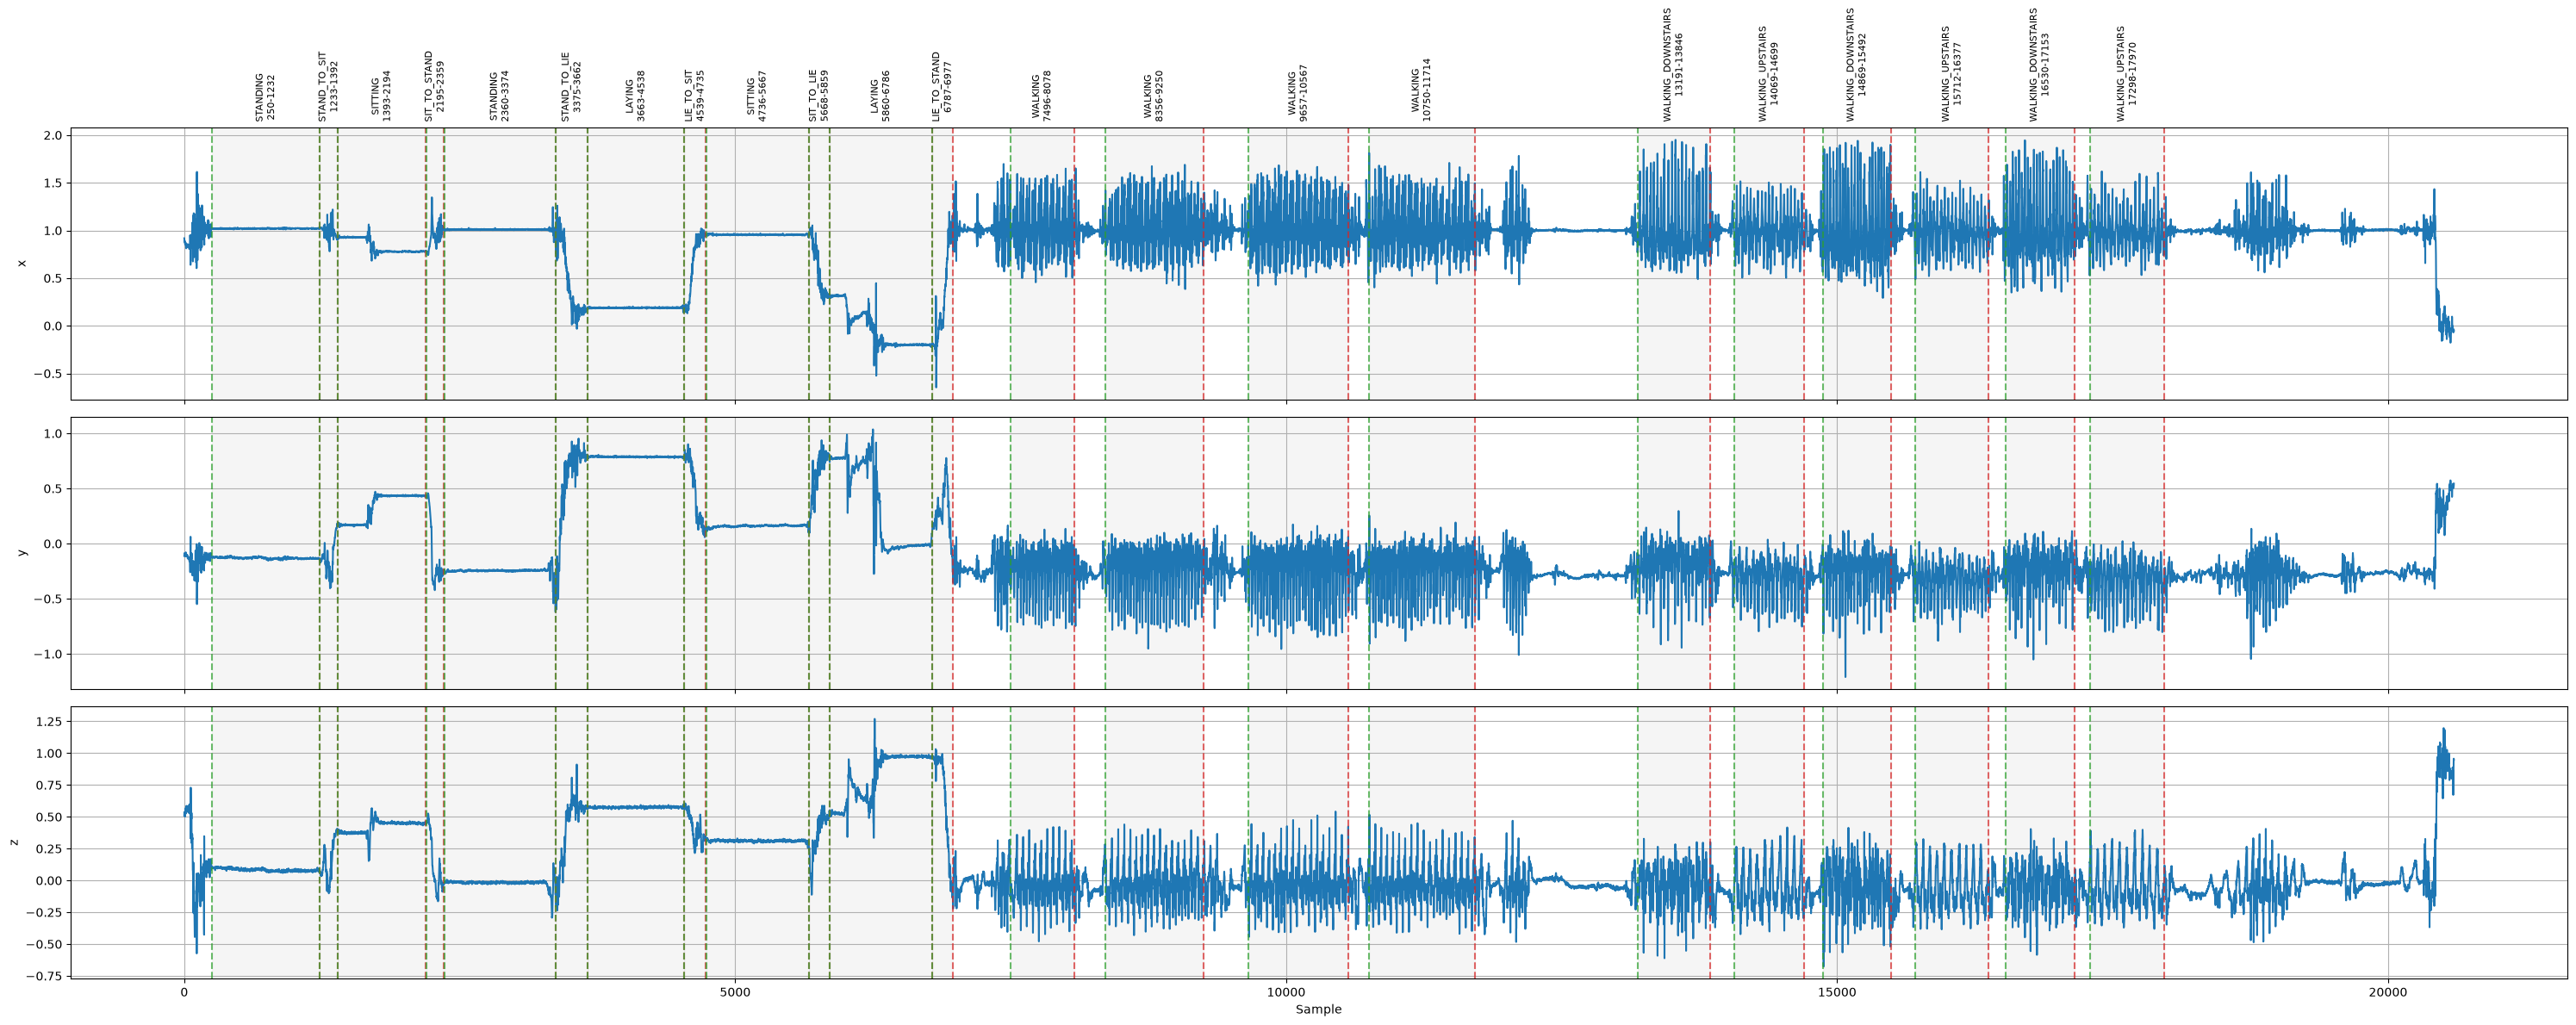

In [3]:

labels_to_plot = labels[
    (labels["experiment"] == 1) & (labels["user"] == 1)
].copy()

fig, axes = plt.subplots(3, 1, figsize=(30, 12), sharex=True)
for ax, column in zip(axes, ["x", "y", "z"]):
    ax.plot(data.index, data[column], label=column)
    ax.set_ylabel(column)
    ax.grid(True)

for _, label in labels_to_plot.iterrows():
    # labels.txt uses one-based sample positions; data.index is zero-based.
    start = label["start"] - 1
    end = label["end"] - 1
    activity_name = label["activity_name"]

    for ax in axes:
        ax.axvline(start, color="tab:green", linestyle="--", alpha=0.7)
        ax.axvline(end, color="tab:red", linestyle="--", alpha=0.7)
        ax.axvspan(start, end, color="gray", alpha=0.08)

    axes[0].text(
        (start + end) / 2,
        1.02,
        f"{activity_name}\n{label['start']}-{label['end']}",
        transform=axes[0].get_xaxis_transform(),
        ha="center",
        va="bottom",
        rotation=90,
        fontsize=8,
    )

axes[-1].set_xlabel("Sample")
fig.tight_layout()
plt.show()

# Task 2 


## The features chosen were:
### - Mean: Captures typical sensor orientation/posture for a specific action
### - Standard deviation: Captures signal variability
### - Range: Captures movement amplitude
### - Mean absolute change: Captures sample-to-sample movement for distinguishing walking from static activities

In [7]:
import re
from pathlib import Path


def extract_features_for_all_acc_files(raw_data_dir):
    """Calculate four features for each labelled segment in every acc file."""
    axes = ["x", "y", "z"]
    raw_data_dir = Path(raw_data_dir)
    labels = pd.read_csv(
        raw_data_dir / "labels.txt",
        sep=r"\s+",
        header=None,
        names=["experiment", "user", "activity", "start", "end"],
    )
    rows = []

    for signal_path in sorted(raw_data_dir.glob("acc_exp*_user*.txt")):
        match = re.fullmatch(r"acc_exp(\d+)_user(\d+)\.txt", signal_path.name)
        if match is None:
            continue
        experiment, user = map(int, match.groups())
        signal = pd.read_csv(
            signal_path, sep=r"\s+", header=None, names=axes
        )
        file_labels = labels[
            (labels["experiment"] == experiment)
            & (labels["user"] == user)
        ]

        for label in file_labels.itertuples(index=False):
            start, end = int(label.start), int(label.end)
            values = signal.iloc[start - 1:end][axes].to_numpy()
            row = {
                "file": signal_path.name,
                "experiment": experiment,
                "user": user,
                "activity": int(label.activity),
                "start": start,
                "end": end,
            }
            for axis_index, axis in enumerate(axes):
                axis_values = values[:, axis_index]
                row[f"{axis}_mean"] = axis_values.mean()
                row[f"{axis}_std"] = axis_values.std()
                row[f"{axis}_range"] = axis_values.max() - axis_values.min()
                row[f"{axis}_mean_abs_change"] = (
                    abs(pd.Series(axis_values).diff()).mean()
                )
            rows.append(row)

    return pd.DataFrame(rows)


segment_features = extract_features_for_all_acc_files("./RawData")
segment_features

,file,experiment,user,activity,start,end,x_mean,x_std,x_range,x_mean_abs_change,y_mean,y_std,y_range,y_mean_abs_change,z_mean,z_std,z_range,z_mean_abs_change
0,acc_exp01_user01.txt,1,1,5,250,1232,1.020469,0.002956,0.020833,0.002434,-0.130777,0.007324,0.045833,0.003317,0.083452,0.010701,0.051389,0.005093
1,acc_exp01_user01.txt,1,1,7,1233,1392,0.991050,0.076649,0.438889,0.025839,-0.124019,0.147493,0.588889,0.019593,0.151875,0.152563,0.506944,0.017794
2,acc_exp01_user01.txt,1,1,4,1393,2194,0.834733,0.075871,0.380556,0.005264,0.333294,0.125102,0.331944,0.004732,0.422837,0.052725,0.415278,0.006114
3,acc_exp01_user01.txt,1,1,8,2195,2359,0.943115,0.121582,0.605556,0.022764,-0.084663,0.301886,0.879167,0.016209,0.137155,0.219560,0.690278,0.012763
4,acc_exp01_user01.txt,1,1,5,2360,3374,1.008577,0.020352,0.484722,0.003968,-0.248655,0.036611,0.494444,0.004576,-0.020421,0.032174,0.429167,0.005823
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1209,acc_exp61_user30.txt,61,30,2,13842,14574,0.993173,0.249811,1.300000,0.061485,-0.207007,0.156755,0.834722,0.044099,-0.008112,0.191716,0.854167,0.032872
1210,acc_exp61_user30.txt,61,30,3,14751,15427,1.018862,0.372394,1.701389,0.107931,-0.066706,0.199794,1.481945,0.076993,0.057866,0.175546,1.480556,0.072915
1211,acc_exp61_user30.txt,61,30,2,15588,16319,0.994202,0.228168,1.188889,0.057127,-0.216033,0.148139,0.772222,0.038117,-0.004597,0.199970,0.830556,0.031954
1212,acc_exp61_user30.txt,61,30,3,16546,17250,1.012935,0.384253,1.608333,0.111119,-0.084417,0.210557,1.625000,0.082582,0.074043,0.167588,1.465278,0.071938


# Task 3

## Results were concatenated in the previous task

### Features are not the exact same across different subject

### Strictly speaking separating 1-3 from 4-12, the mean absolute change is the biggest differentiator. That feature for a single axis in activities 1-3 is significantly higher than its counterpart in 4-12.

### Variations between subject may include different body propotions affecting the accelerometers differently, and a person's way of getting up is not the exact same for another person

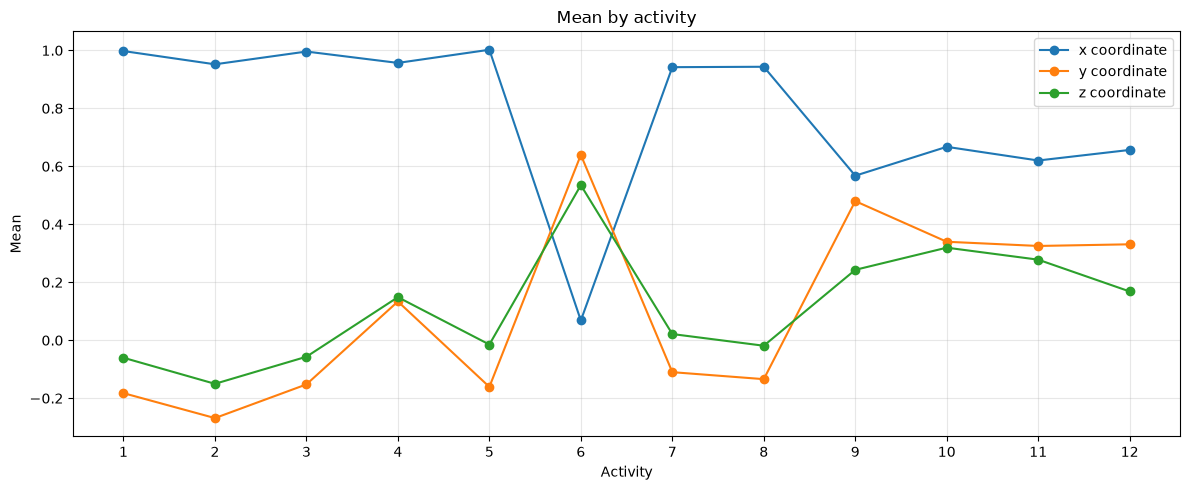

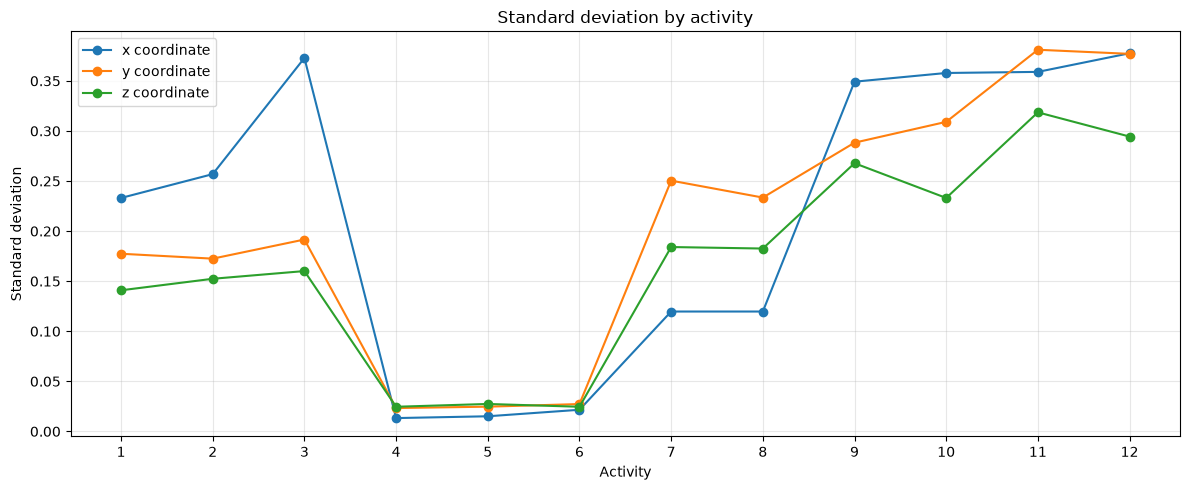

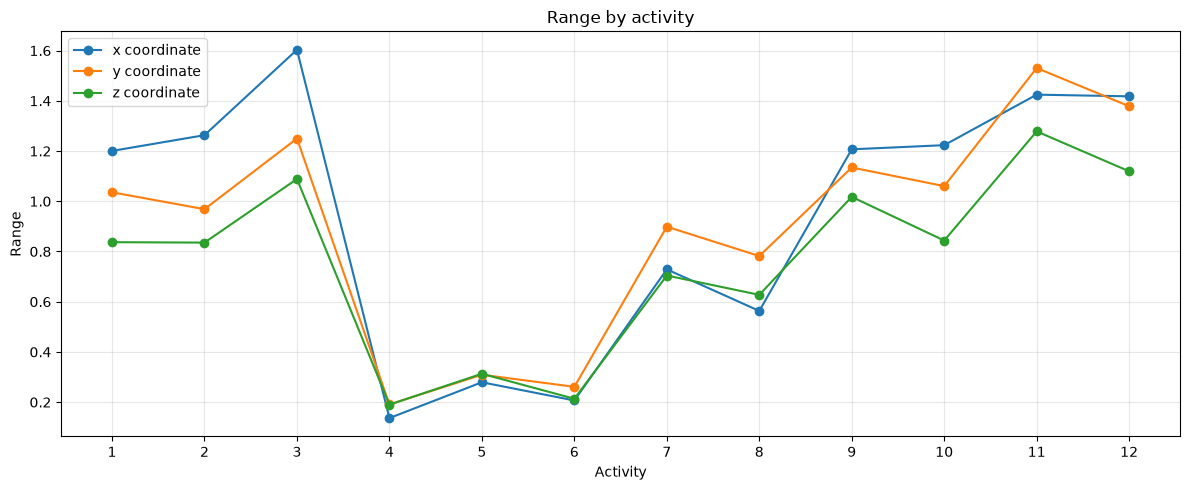

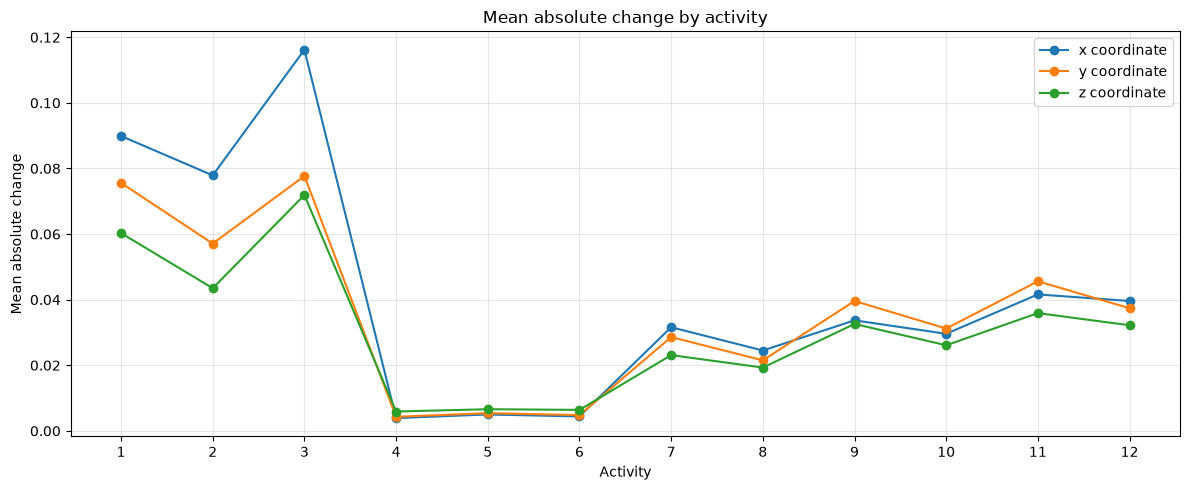

In [17]:
feature_columns = [
    column for column in segment_features.columns
    if any(column.endswith(suffix) for suffix in
           ["_mean", "_std", "_range", "_mean_abs_change"])
]

activity_summary = (
    segment_features.groupby("activity")[feature_columns]
    .agg(["mean", "std"])
    .round(4)
)

subject_activity_means = (
    segment_features.groupby(["activity", "user"])[feature_columns]
    .mean()
    .round(4)
)

between_subject_summary = pd.concat(
    {
        "subject_mean_range": subject_activity_means.groupby(level=0).max()
        - subject_activity_means.groupby(level=0).min(),
        "subject_mean_std": subject_activity_means.groupby(level=0).std(),
    },
    axis=1,
).round(4)

#display(activity_summary)
#display(subject_activity_means.head(20))
#display(between_subject_summary)

metrics = {
    "mean": "Mean",
    "std": "Standard deviation",
    "range": "Range",
    "mean_abs_change": "Mean absolute change",
}
axes = ["x", "y", "z"]

for metric, title in metrics.items():
    plt.figure(figsize=(12, 5))
    for axis in axes:
        plt.plot(
            activity_summary.index,
            activity_summary[(f"{axis}_{metric}", "mean")],
            marker="o",
            label=f"{axis} coordinate",
        )
    plt.xticks(activity_summary.index)
    plt.xlabel("Activity")
    plt.ylabel(title)
    plt.title(f"{title} by activity")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()